# 05 · Proposed Metric: Transformation-Conditioned Explanation Reliability Score (TCERS)

**Status.** TCERS is a *proposed* composite score introduced for this study. It is **not** an established or validated scientific metric. Results must be read as descriptive evidence about explanation stability, not as a universal ranking of explanation methods.

## Definition

For sample $x$, explanation method $m$, and target class $\hat{y}$:

$$\mathcal{V}(x) = \{t \in \mathcal{T} : f(t(x)) = f(x)\},$$

$$\mathrm{TCERS}(x, m) = \frac{1}{|\mathcal{V}(x)|}\sum_{t \in \mathcal{V}(x)} \left[w_1\,\mathrm{SSIM}(g_m(x), g_m(t(x))) + w_2\,\rho_s(g_m(x), g_m(t(x))) + w_3\,\cos(g_m(x), g_m(t(x)))\right].$$

Default weights are equal, $w_1 = w_2 = w_3 = 1/3$. Transformations that change the prediction are excluded and reported separately through `valid_transformations`, `excluded_transformations`, and `prediction_consistency`.

## Why condition on prediction preservation?

A method that produces a stable map while the classifier changes its answer is not reliably explaining the *same* decision. Conditioning on prediction preservation avoids rewarding explanations of a different class. The exclusion count is retained as a diagnostic rather than discarded.

## Artifacts

- `experiments/results/tcers_per_sample.csv`
- `experiments/results/tcers_summary.csv`
- `experiments/results/tcers_weight_sensitivity.csv`
- `figures/tcers_distribution.png`
- `figures/tcers_confidence_intervals.png`
- `figures/tcers_weight_sensitivity.png`

## Environment and input table

This notebook consumes the combined stability table produced by Notebook 04. If the file is missing, run Notebook 04 first; TCERS is never computed from fabricated or cached example values.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image as DisplayImage, display
from scipy.stats import t

from src.config import ExperimentConfig
from src.metrics.stability import tcers
from src.utils import seed_everything

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})

config = ExperimentConfig()
config.create_directories()
seed_everything(config.seed)

raw_path = config.output_root / "stability_raw.csv"
if not raw_path.exists():
    raise FileNotFoundError("stability_raw.csv not found. Run notebook 04 first.")

raw_results = pd.read_csv(raw_path)
print(f"Loaded {len(raw_results)} observations from {raw_path}")
print(f"Methods: {sorted(raw_results['method'].unique())}")
print(f"Samples: {sorted(raw_results['sample'].unique())}")

Loaded 336 observations from experiments\results\stability_raw.csv
Methods: ['Grad-CAM', 'Integrated Gradients', 'Occlusion']
Samples: [0, 1, 2, 3, 4, 5, 6, 7]


## Per-sample TCERS

TCERS is computed per sample and method, using only prediction-preserving transformations. `total_transformations` is the number of perturbations applied to that sample by that method, so the excluded count is exact.

In [2]:
valid = raw_results[raw_results["prediction_unchanged"]].copy()

records = []
for (method, sample), frame in raw_results.groupby(["method", "sample"]):
    valid_frame = frame[frame["prediction_unchanged"]]
    summary = tcers(
        valid_frame[["ssim", "spearman", "cosine"]].to_dict("records"),
        min_valid=1,
        total_transformations=len(frame),
    )
    summary.update({
        "method": method,
        "sample": int(sample),
        "prediction_consistency": float(frame["prediction_unchanged"].mean()),
    })
    records.append(summary)

tcers_table = pd.DataFrame(records).sort_values(["method", "sample"]).reset_index(drop=True)
tcers_table.to_csv(config.output_root / "tcers_per_sample.csv", index=False)
tcers_table

,tcers,valid_transformations,excluded_transformations,method,sample,prediction_consistency
0,0.894541,13,1,Grad-CAM,0,0.928571
1,0.951798,14,0,Grad-CAM,1,1.000000
2,0.969570,14,0,Grad-CAM,2,1.000000
3,0.860080,12,2,Grad-CAM,3,0.857143
4,0.939457,14,0,Grad-CAM,4,1.000000
5,0.764381,11,3,Grad-CAM,5,0.785714
6,0.756561,11,3,Grad-CAM,6,0.785714
7,0.902421,14,0,Grad-CAM,7,1.000000
8,0.664014,13,1,Integrated Gradients,0,0.928571
9,0.671018,14,0,Integrated Gradients,1,1.000000


## Method-level summary

The summary reports the mean, dispersion, and a 95% confidence interval for the mean. With small samples, the interval is wide and should be interpreted as uncertainty about the mean, not as a prediction interval for individual samples.

In [3]:
def mean_confidence_interval(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    if len(values) < 2:
        return float("nan"), float("nan")
    standard_error = values.std(ddof=1) / np.sqrt(len(values))
    half_width = t.ppf(0.5 + confidence / 2, df=len(values) - 1) * standard_error
    return float(values.mean() - half_width), float(values.mean() + half_width)

summary_rows = []
for method, frame in tcers_table.groupby("method"):
    values = frame["tcers"].dropna().to_numpy()
    lower, upper = mean_confidence_interval(values)
    summary_rows.append({
        "method": method,
        "samples": len(frame),
        "valid_samples": len(values),
        "tcers_mean": float(np.mean(values)) if len(values) else float("nan"),
        "tcers_std": float(np.std(values, ddof=1)) if len(values) > 1 else float("nan"),
        "tcers_median": float(np.median(values)) if len(values) else float("nan"),
        "ci95_lower": lower,
        "ci95_upper": upper,
        "mean_valid_transformations": float(frame["valid_transformations"].mean()),
        "mean_excluded_transformations": float(frame["excluded_transformations"].mean()),
        "prediction_consistency": float(frame["prediction_consistency"].mean()),
    })

summary = pd.DataFrame(summary_rows).sort_values("tcers_mean", ascending=False)
summary.to_csv(config.output_root / "tcers_summary.csv", index=False)
summary

,method,samples,valid_samples,tcers_mean,tcers_std,tcers_median,ci95_lower,ci95_upper,mean_valid_transformations,mean_excluded_transformations,prediction_consistency
0,Grad-CAM,8,8,0.879851,0.081441,0.898481,0.811764,0.947938,12.875,1.125,0.919643
2,Occlusion,8,8,0.771700,0.048592,0.750474,0.731076,0.812323,12.875,1.125,0.919643
1,Integrated Gradients,8,8,0.671931,0.042770,0.672286,0.636175,0.707688,12.875,1.125,0.919643


## Weight sensitivity

The composite score depends on the chosen weights. This table recomputes the method-level mean for equal, SSIM-heavy, Spearman-heavy, and cosine-heavy weightings. A conclusion that reverses under reasonable weights should be reported as weight-dependent.

In [4]:
weight_sets = {
    "equal": (1 / 3, 1 / 3, 1 / 3),
    "ssim_heavy": (0.6, 0.2, 0.2),
    "spearman_heavy": (0.2, 0.6, 0.2),
    "cosine_heavy": (0.2, 0.2, 0.6),
}

sensitivity_rows = []
for weighting, weights in weight_sets.items():
    for method, frame in valid.groupby("method"):
        per_sample = []
        for sample, sample_frame in frame.groupby("sample"):
            values = (
                weights[0] * sample_frame["ssim"]
                + weights[1] * sample_frame["spearman"]
                + weights[2] * sample_frame["cosine"]
            )
            per_sample.append(values.mean())
        sensitivity_rows.append({
            "weighting": weighting,
            "method": method,
            "mean_tcers": float(np.mean(per_sample)) if per_sample else float("nan"),
            "samples": len(per_sample),
        })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(config.output_root / "tcers_weight_sensitivity.csv", index=False)
sensitivity.pivot(index="method", columns="weighting", values="mean_tcers")

weighting,cosine_heavy,equal,spearman_heavy,ssim_heavy
method,,,,
Grad-CAM,0.901608,0.879851,0.877849,0.860095
Integrated Gradients,0.675681,0.671931,0.648183,0.691930
Occlusion,0.806604,0.771700,0.753576,0.754918


## Visual diagnostics

The distribution plot shows per-sample variability, the interval plot shows uncertainty about method-level means, and the sensitivity plot shows whether rankings depend on the composite weights.

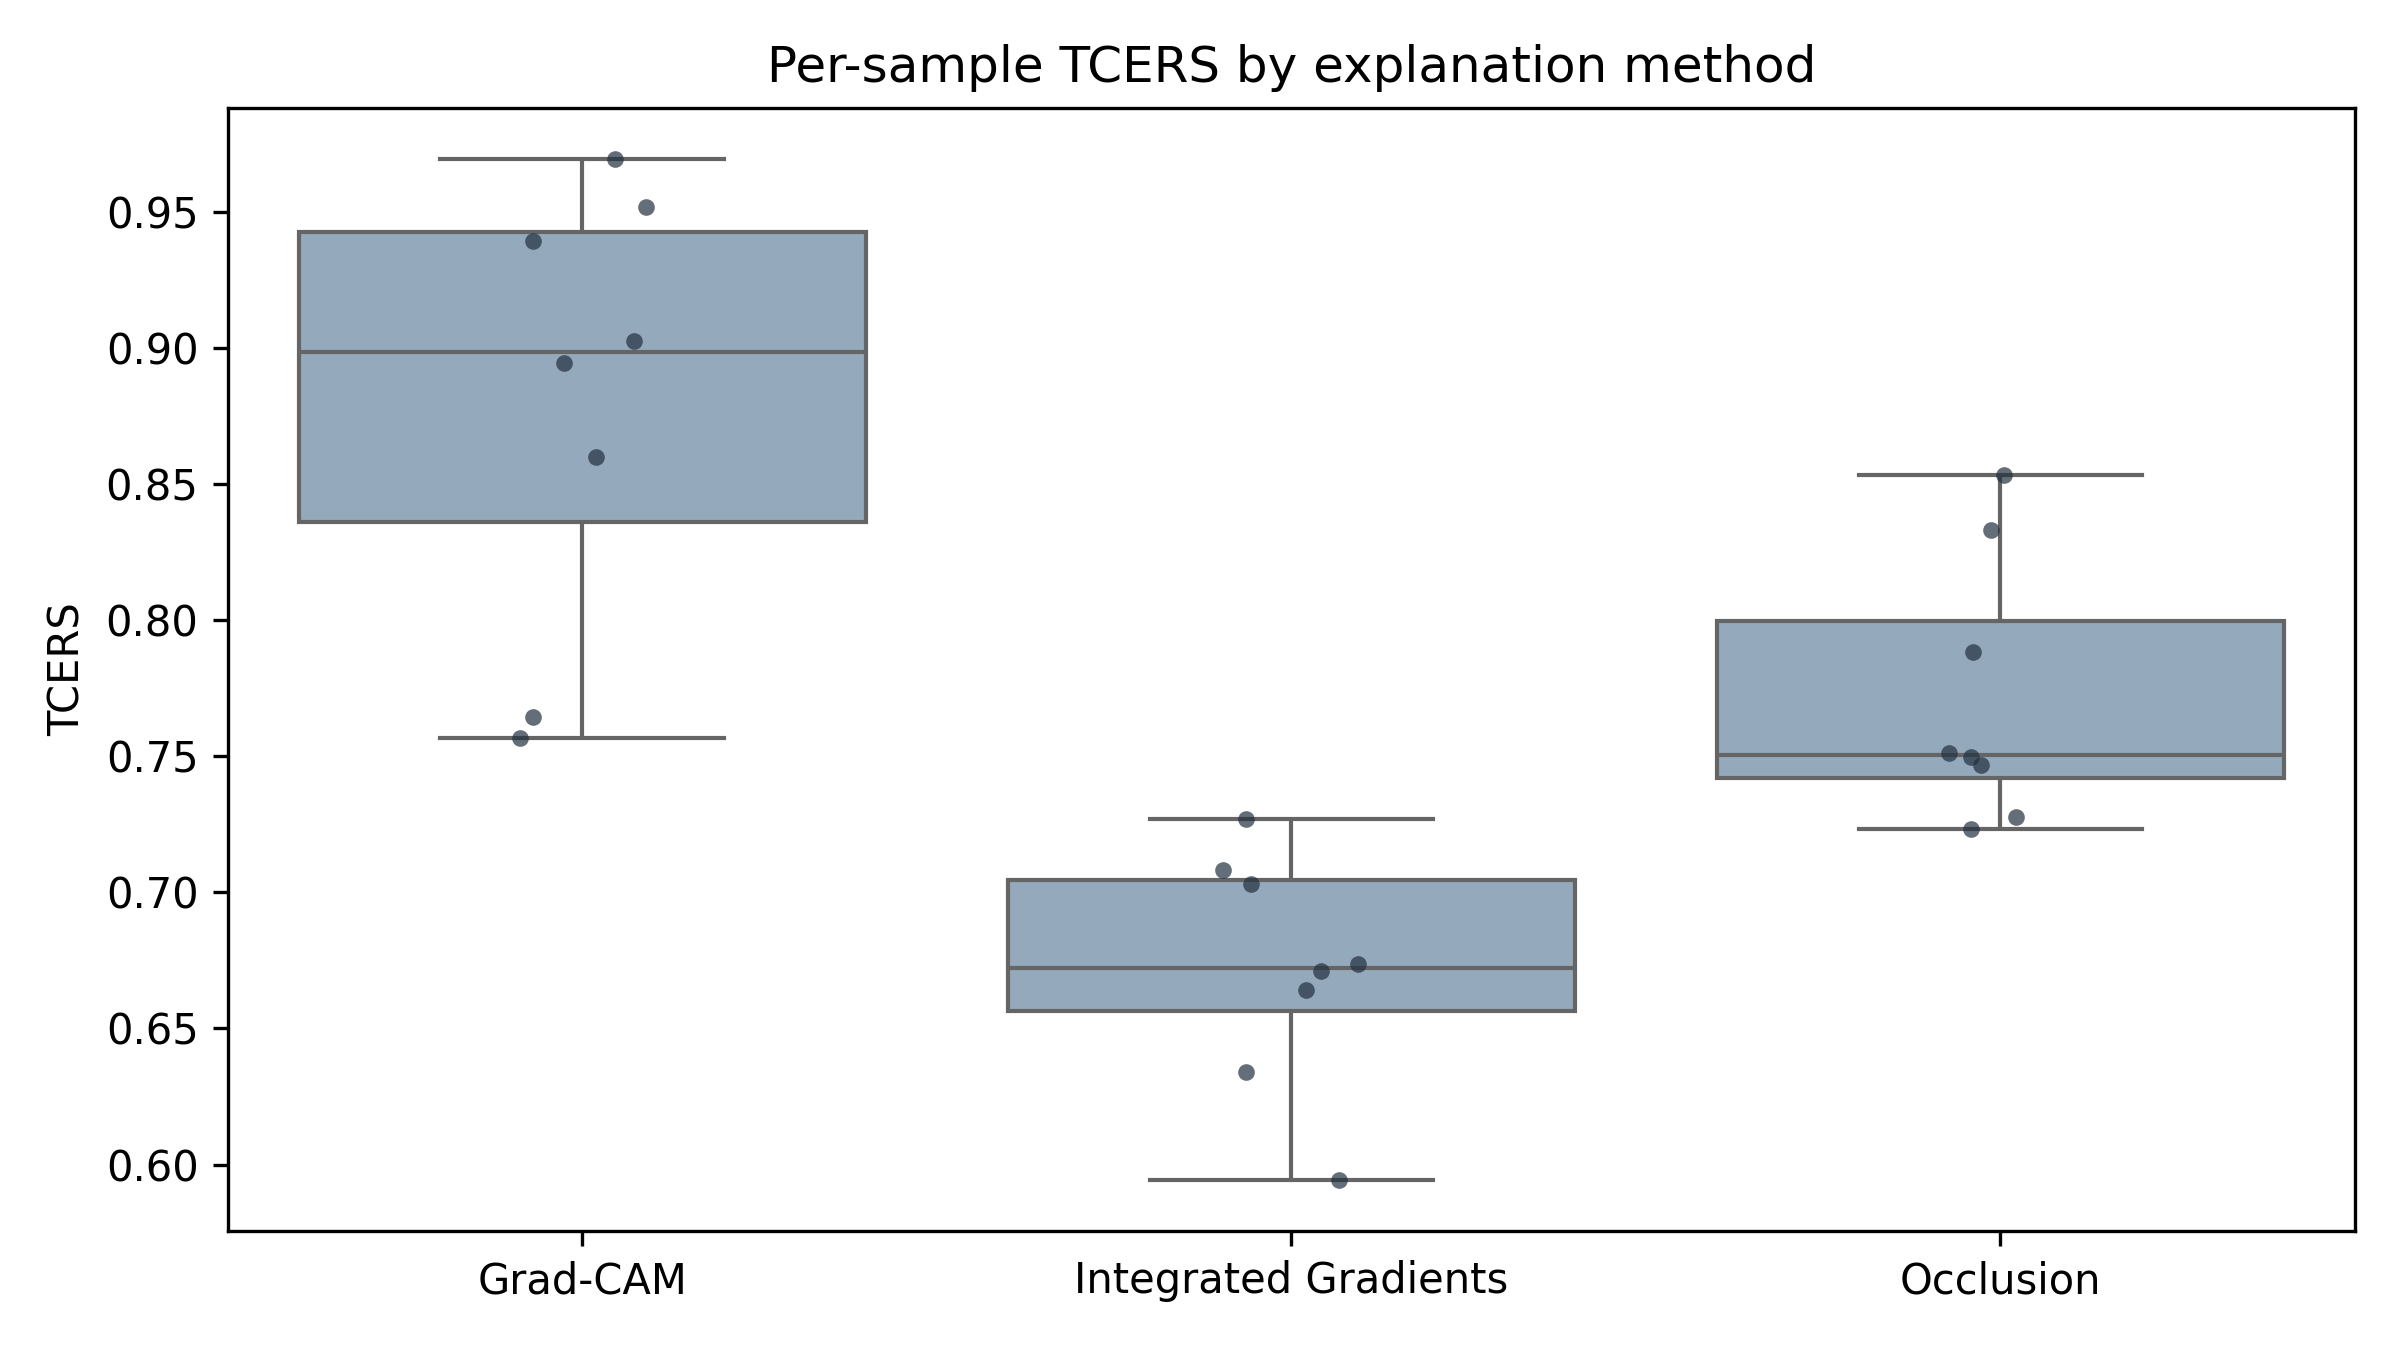

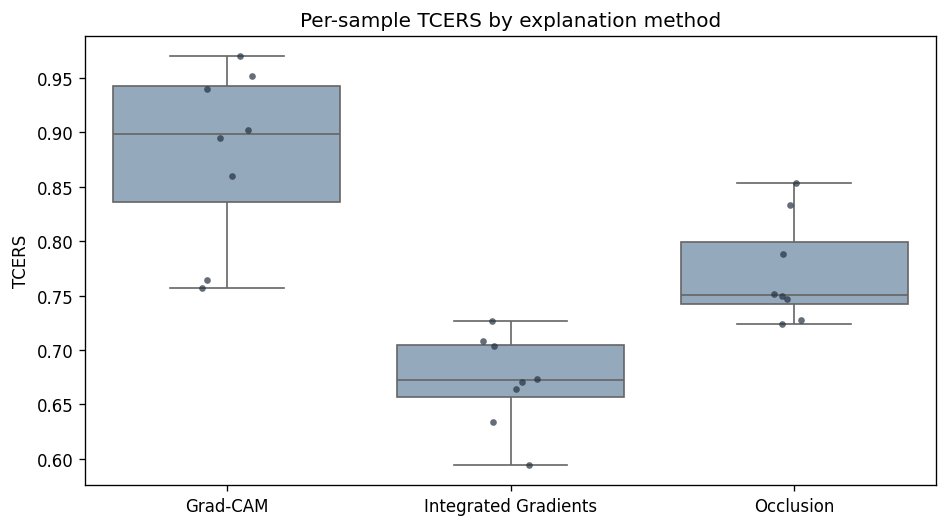

In [5]:
figure, axis = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=tcers_table, x="method", y="tcers", color="#8EA9C1", ax=axis)
sns.stripplot(data=tcers_table, x="method", y="tcers", color="#22313F", size=4, alpha=0.7, ax=axis)
axis.set(title="Per-sample TCERS by explanation method", xlabel="", ylabel="TCERS")
figure.tight_layout()
figure.savefig(Path("figures") / "tcers_distribution.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "tcers_distribution.png")))

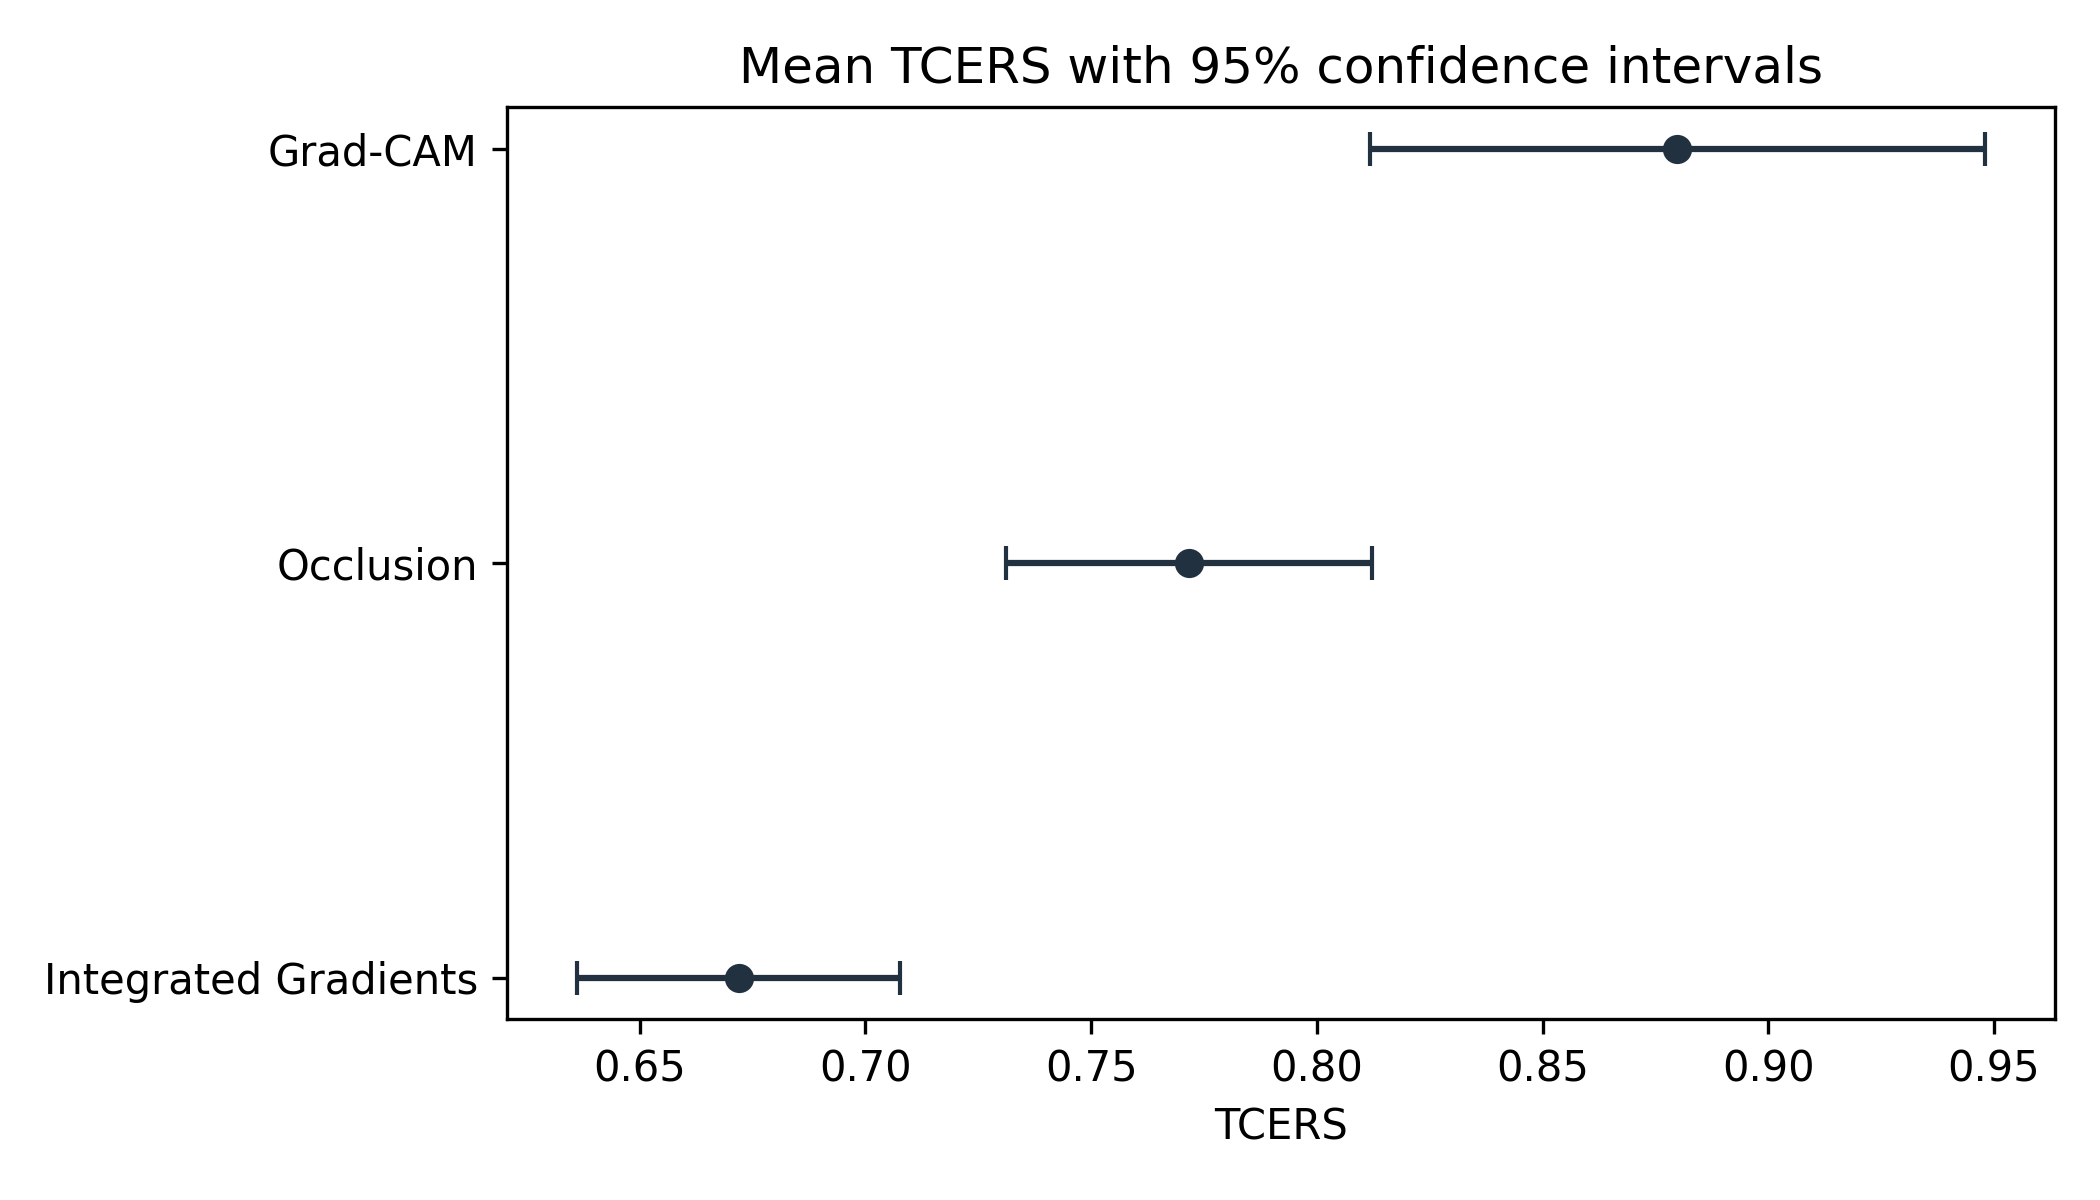

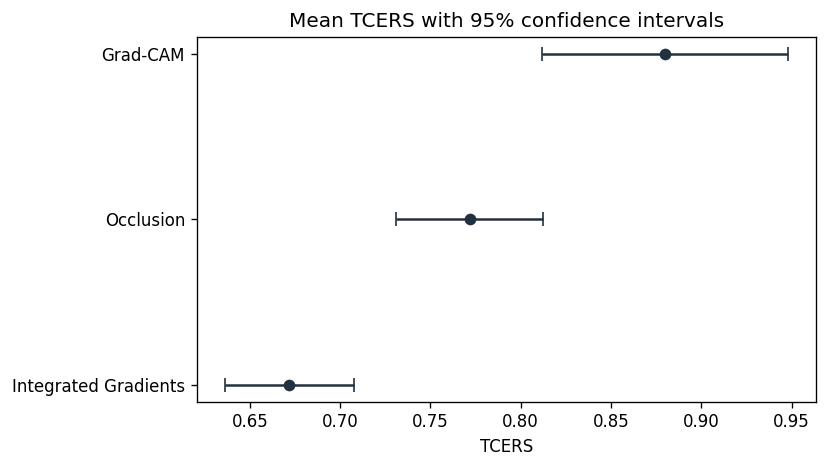

In [6]:
figure, axis = plt.subplots(figsize=(7, 4))
positions = np.arange(len(summary))
axis.errorbar(
    summary["tcers_mean"],
    positions,
    xerr=[
        summary["tcers_mean"] - summary["ci95_lower"],
        summary["ci95_upper"] - summary["tcers_mean"],
    ],
    fmt="o",
    capsize=4,
    color="#22313F",
)
axis.set_yticks(positions, summary["method"])
axis.set(title="Mean TCERS with 95% confidence intervals", xlabel="TCERS", ylabel="")
axis.invert_yaxis()
figure.tight_layout()
figure.savefig(Path("figures") / "tcers_confidence_intervals.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "tcers_confidence_intervals.png")))

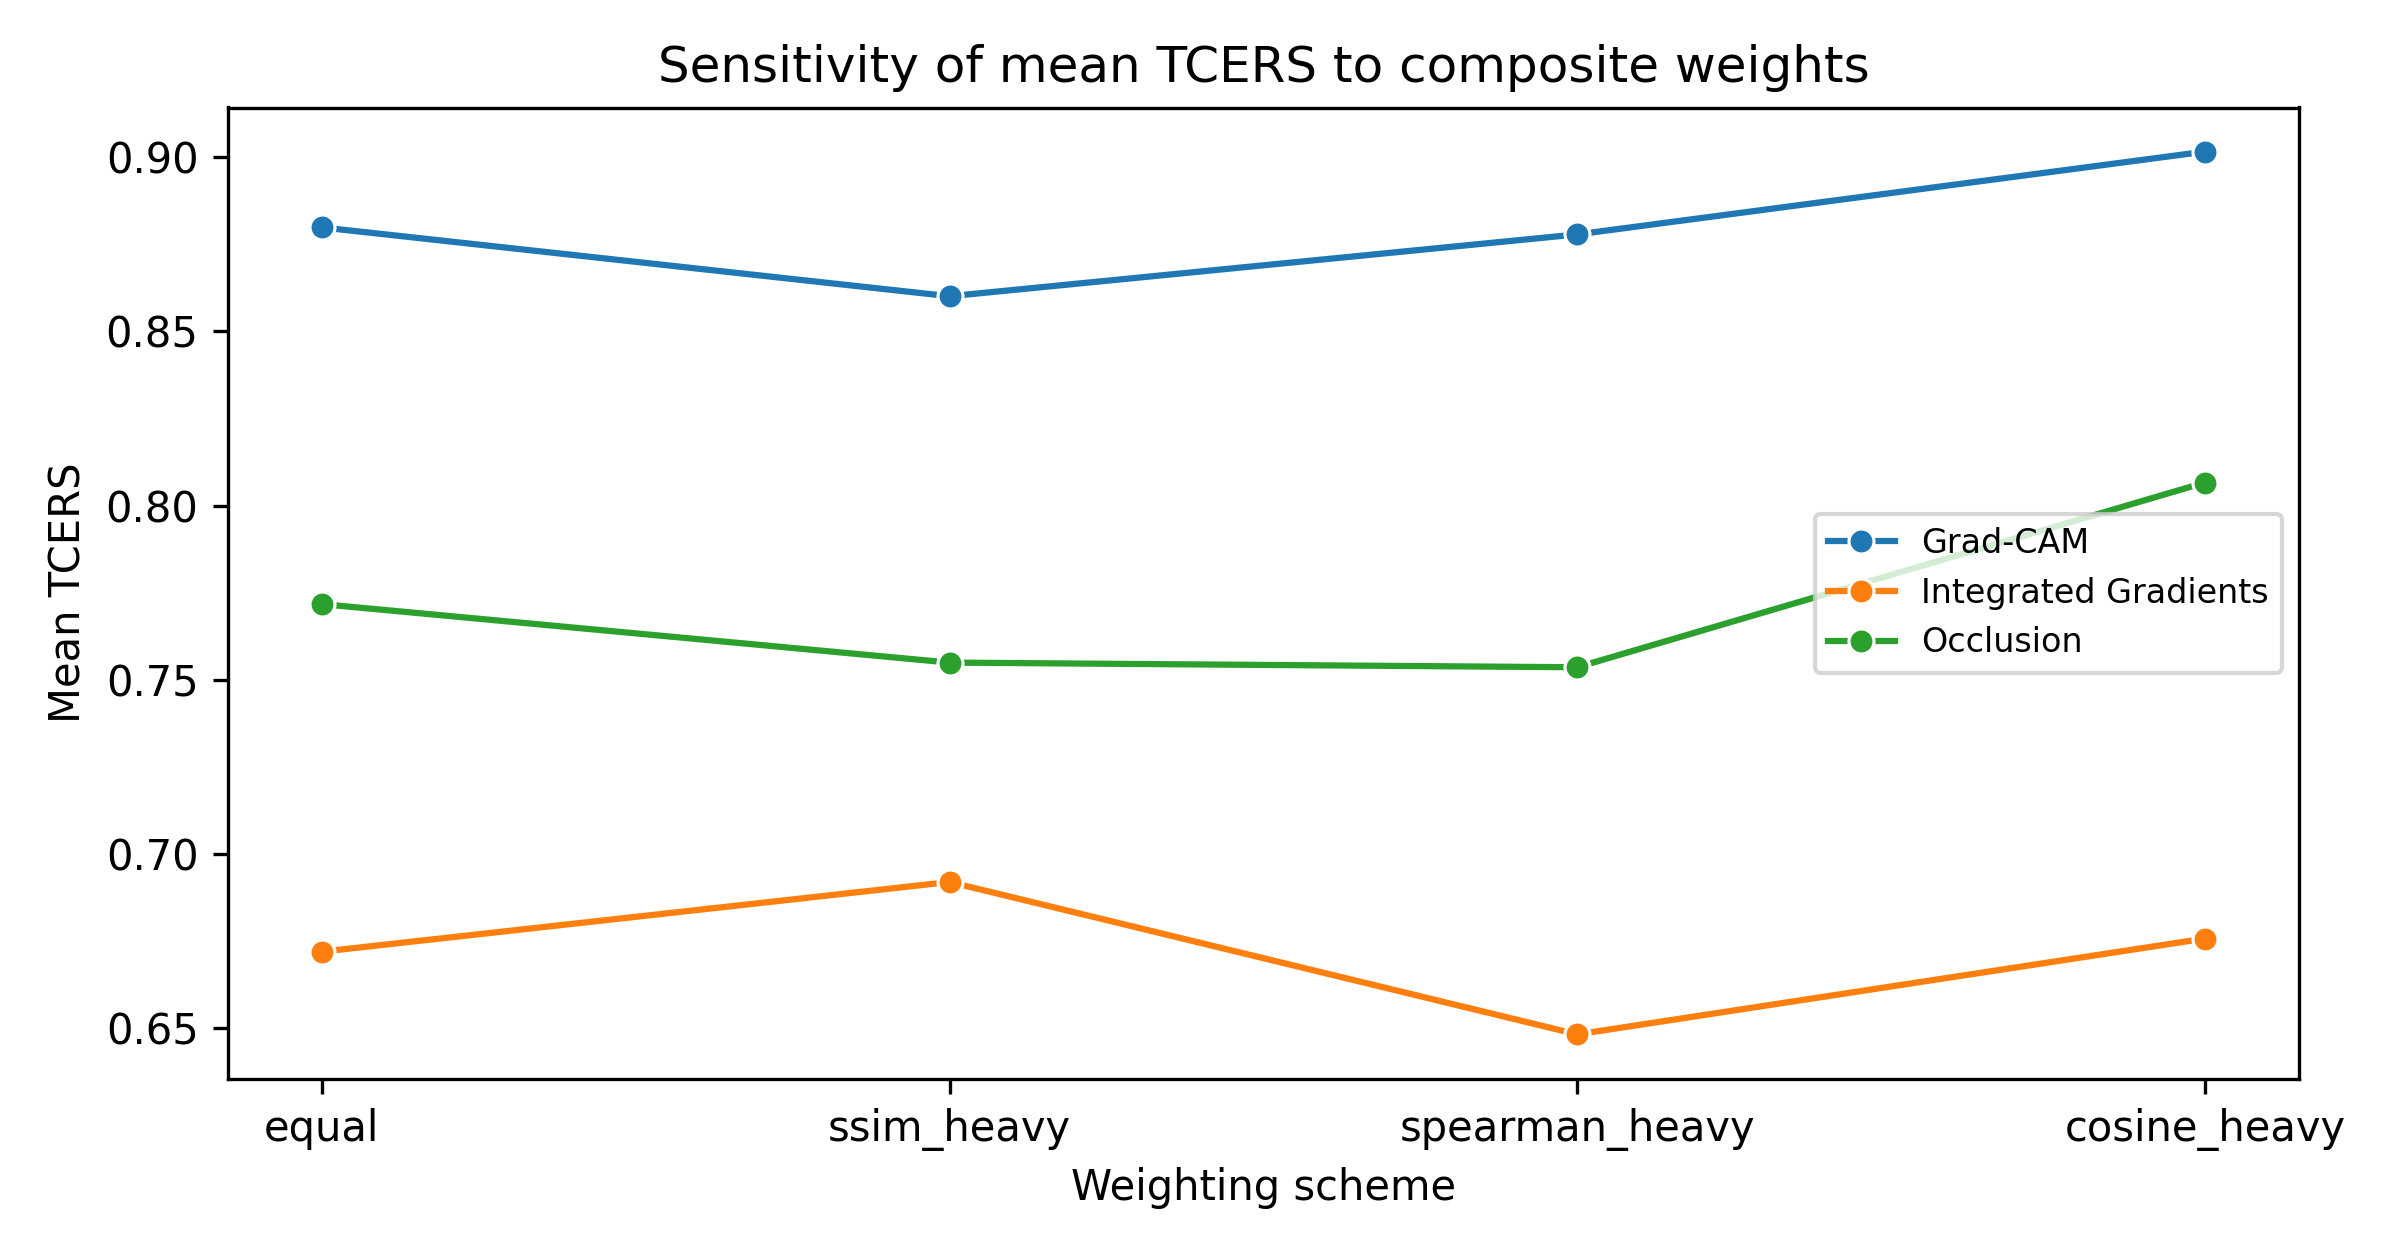

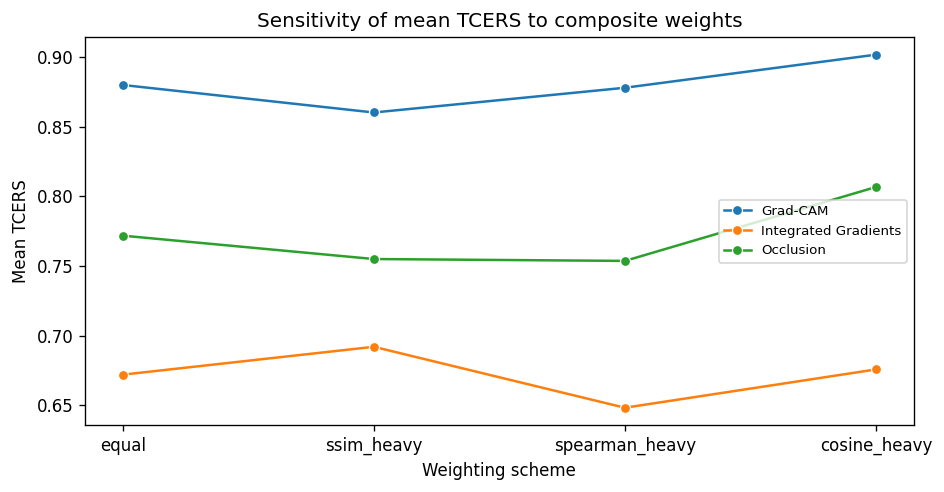

In [7]:
figure, axis = plt.subplots(figsize=(8, 4.2))
sns.lineplot(data=sensitivity, x="weighting", y="mean_tcers", hue="method", marker="o", ax=axis)
axis.set(title="Sensitivity of mean TCERS to composite weights", xlabel="Weighting scheme", ylabel="Mean TCERS")
axis.legend(fontsize=8)
figure.tight_layout()
figure.savefig(Path("figures") / "tcers_weight_sensitivity.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "tcers_weight_sensitivity.png")))

## Limitations and reporting guidance

- **Composite weighting is a design choice.** The weight-sensitivity table shows whether conclusions depend on it. Report the full weight set, not only the equal-weight score.
- **The components are not exchangeable.** SSIM, Spearman correlation, and cosine similarity measure different properties; averaging them loses information. Always report the three components alongside TCERS.
- **Exclusion changes the estimand.** TCERS describes stability *conditional on prediction preservation*. Prediction consistency must be reported as a separate outcome.
- **Small samples produce unstable means.** Use the per-sample table for resampling-based uncertainty, and do not interpret ranking without confidence intervals.
- **Not a substitute for faithfulness.** Stability is not correctness. A method can be consistently wrong. Ground-truth or deletion-based faithfulness tests remain necessary.

Proceed to `06_statistical_analysis.ipynb` for uncertainty quantification and paired tests.